# Horse Training Data Analysis and Visualization

This Jupyter Notebook focuses on analyzing and visualizing horse training data using metrics derived from a JSON dataset. The primary objectives include:

1. **Data Processing**:
   - Load and parse a JSON file containing horse training data.
   - Flatten nested structures into a tabular format using pandas for easier analysis.
   - Sort and clean the data for visualization.

2. **Visualization of Metrics**:
   - **Trot Distance Load**: Visualize the daily trot distance load for each horse over time, both individually and in subplots for all horses.
   - **ACWR Metrics**: Analyze and plot Acute:Chronic Workload Ratio (ACWR) metrics for:
     - Distance
     - Duration
     - iTrimp (internal training load)
   - Highlight risk categories (e.g., undertraining, optimal, overreaching, overtraining) based on ACWR thresholds.

3. **Combined ACWR Comparison**:
   - Compare multiple ACWR metrics (Distance, Duration, iTrimp) for each horse in a single plot.

The notebook uses Python libraries such as `pandas`, `matplotlib`, and `seaborn` for data manipulation and visualization. It provides insights into horse training performance and workload management, helping identify trends and potential risks.

In [1]:
import json
import pandas as pd

# Use relative path to the file
path_horse_readiness_json = "datasets/Horse_Readiness_FULLY_FIXED.json"


with open(path_horse_readiness_json, "r", encoding="utf-8") as f:
    data = json.load(f)

records = []

for entry in data:
    horse_id = entry.get("HorseID", "unknown")
    acwr = entry.get("ACWR", {})

    for date, metrics in acwr.items():
        flat_record = {"HorseID": horse_id, "Date": date}

        for category, submetrics in metrics.items():
            for subname, values in submetrics.items():
                for k, v in values.items():
                    column_name = f"{category}_{subname}_{k}"
                    flat_record[column_name] = float(v) if v.replace('.', '', 1).isdigit() else v

        records.append(flat_record)

df = pd.DataFrame(records)

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.sort_values(["HorseID", "Date"], inplace=True)

display(df.sample(10))

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
502,257,2024-03-20,0.00,34.30,32.63,29.30,1.11,0.00,14.80,13.32,...,0.00,8.55,8.41,6.93,1.21,0.0,0.0,0.34,0.45,0.76
2130,483,2024-09-02,0.00,8.16,5.66,3.86,1.47,0.00,5.55,3.86,...,0.00,0.04,0.03,0.08,0.38,0.0,0.0,0.02,0.07,0.29
916,311,2022-08-25,0.00,7.51,5.73,2.92,1.96,0.00,1.10,0.85,...,0.00,6.87,5.24,2.38,2.20,0.0,0.0,0.02,0.07,0.29
2104,483,2024-08-07,3.19,3.19,1.72,4.42,0.39,0.37,0.37,0.63,...,0.37,0.37,0.11,0.09,1.22,0.0,0.0,0.02,0.07,0.29
599,257,2024-06-26,6.33,36.55,35.66,25.03,1.42,3.22,17.48,16.60,...,0.00,5.64,7.70,5.20,1.48,0.0,0.0,0.02,0.04,0.50
2206,483,2024-11-17,0.00,8.48,9.79,9.40,1.04,0.00,5.22,6.25,...,0.00,0.00,0.03,0.07,0.43,0.0,0.0,0.02,0.07,0.29
2058,483,2024-06-22,6.80,16.87,18.35,12.83,1.43,4.63,9.92,9.55,...,0.00,0.00,0.02,0.23,0.09,0.0,0.0,0.02,0.07,0.29
41,257,2022-12-15,0.00,14.11,16.56,24.49,0.68,0.00,3.36,5.18,...,0.00,4.40,5.25,7.99,0.66,0.0,0.0,0.00,0.00,0.00
1847,483,2023-11-25,4.02,12.67,5.46,1.71,3.19,2.80,7.37,3.03,...,0.00,0.14,0.09,0.03,3.00,0.0,0.0,0.00,0.00,0.00
1964,483,2024-03-20,7.12,15.30,13.88,15.15,0.92,3.66,7.98,7.20,...,0.00,0.00,0.31,0.52,0.60,0.0,0.0,0.00,0.00,0.00


## Trost distance load over time per horse
One Chart per Horse (Sequential Display)

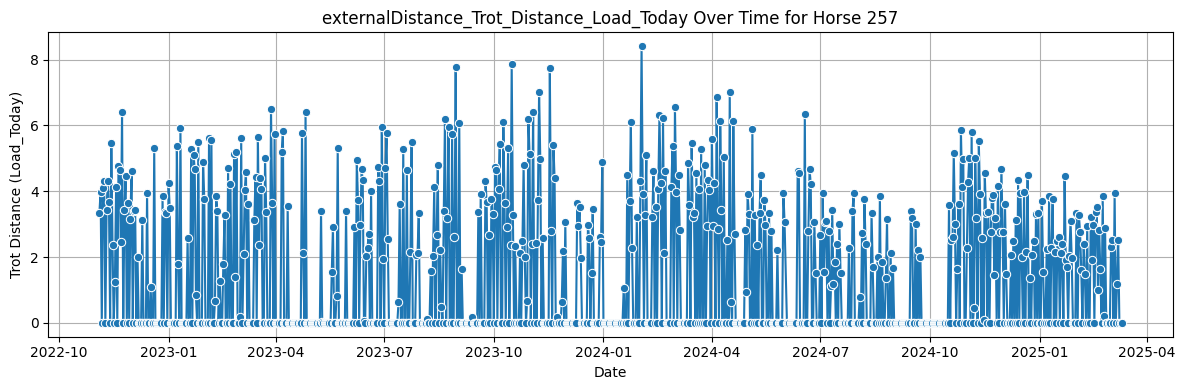

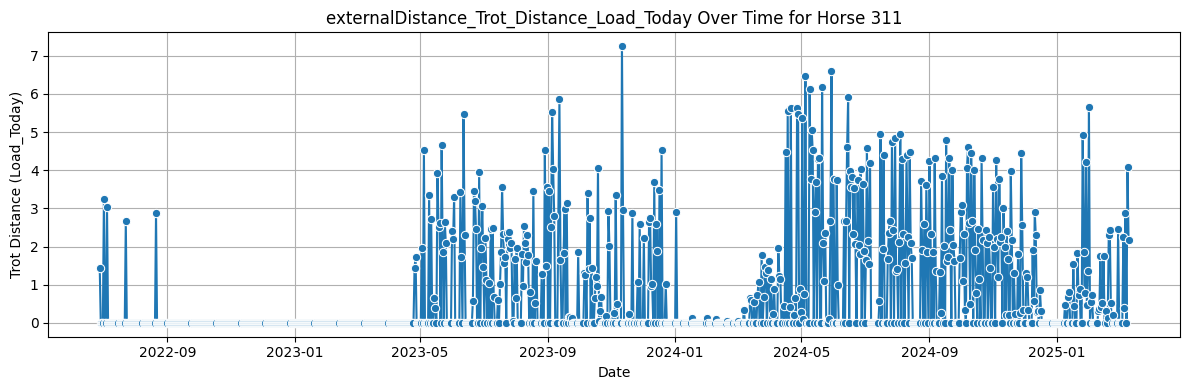

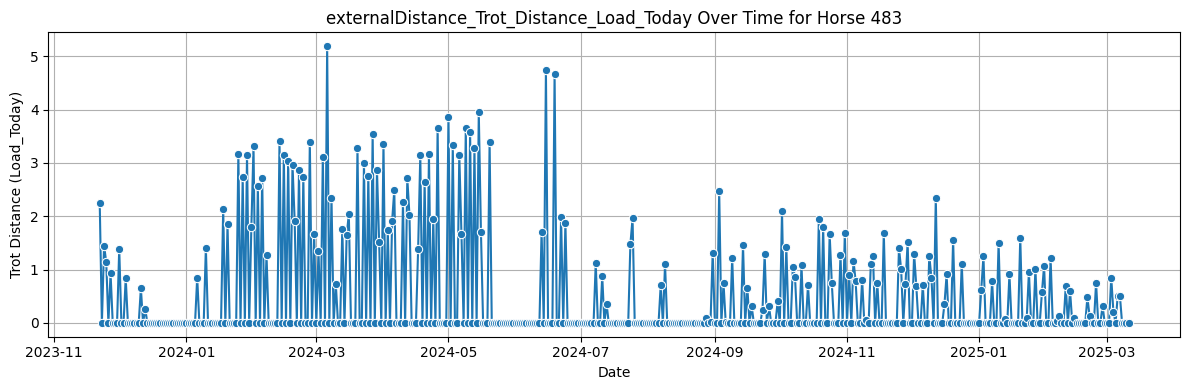

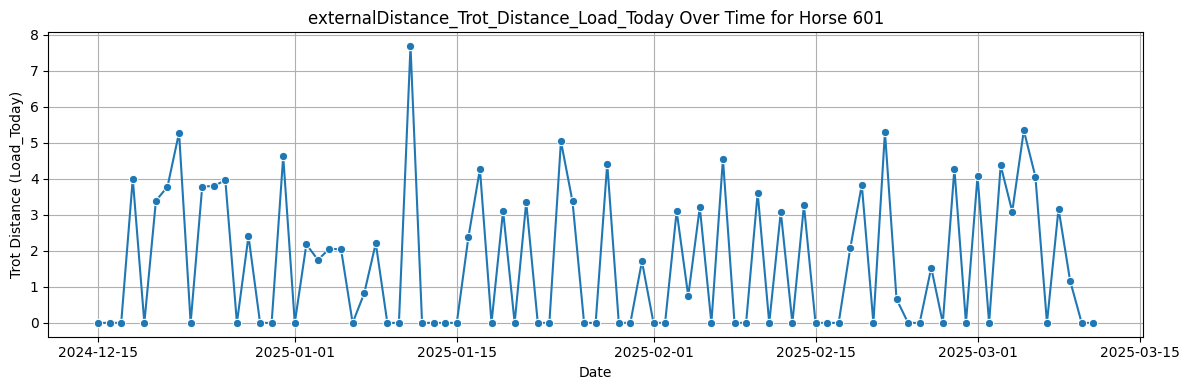

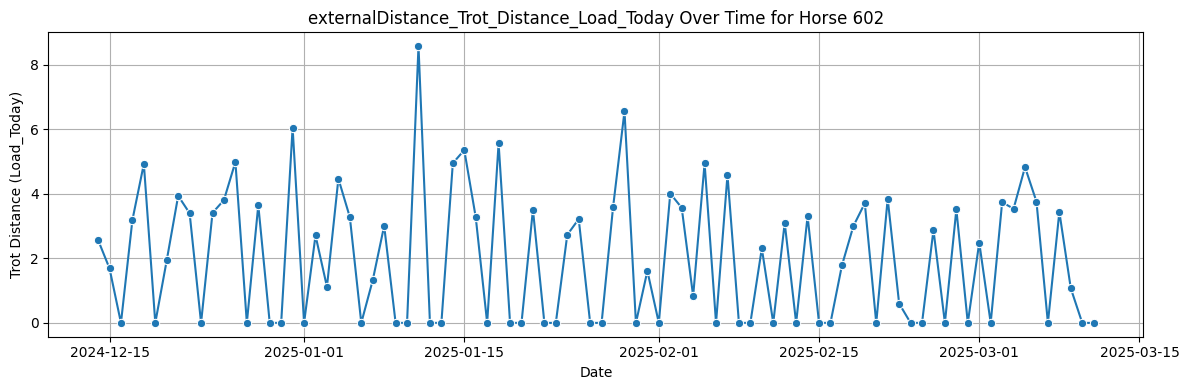

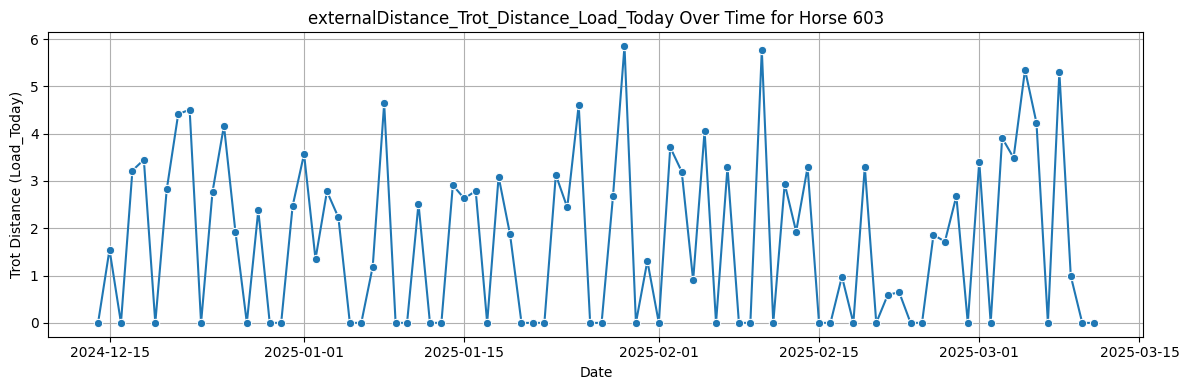

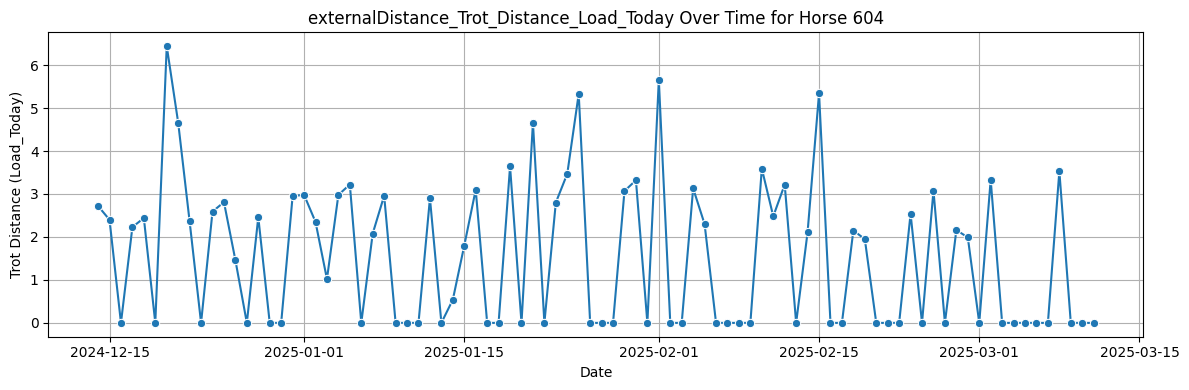

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set metric to visualize
metric = 'externalDistance_Trot_Distance_Load_Today'

# Filter and convert values
df_filtered = df[['HorseID', 'Date', metric]].dropna()
df_filtered[metric] = df_filtered[metric].astype(float)

# Get unique horses
unique_horses = df_filtered['HorseID'].unique()

# Plot one figure per horse
for horse_id in unique_horses:
    horse_df = df_filtered[df_filtered['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=metric, marker="o")
    plt.title(f'{metric} Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('Trot Distance (Load_Today)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


Each plot corresponds to a single horse's daily performance in the Trot way of moving, specifically:
Metric Plotted: externalDistance_Trot_Distance_Load_Today

X-axis: Dates (from training logs)

Y-axis: Distance covered in trot on that day (in whatever unit the dataset uses, likely kilometers)

All Horses in Subplots (Small Multiples)

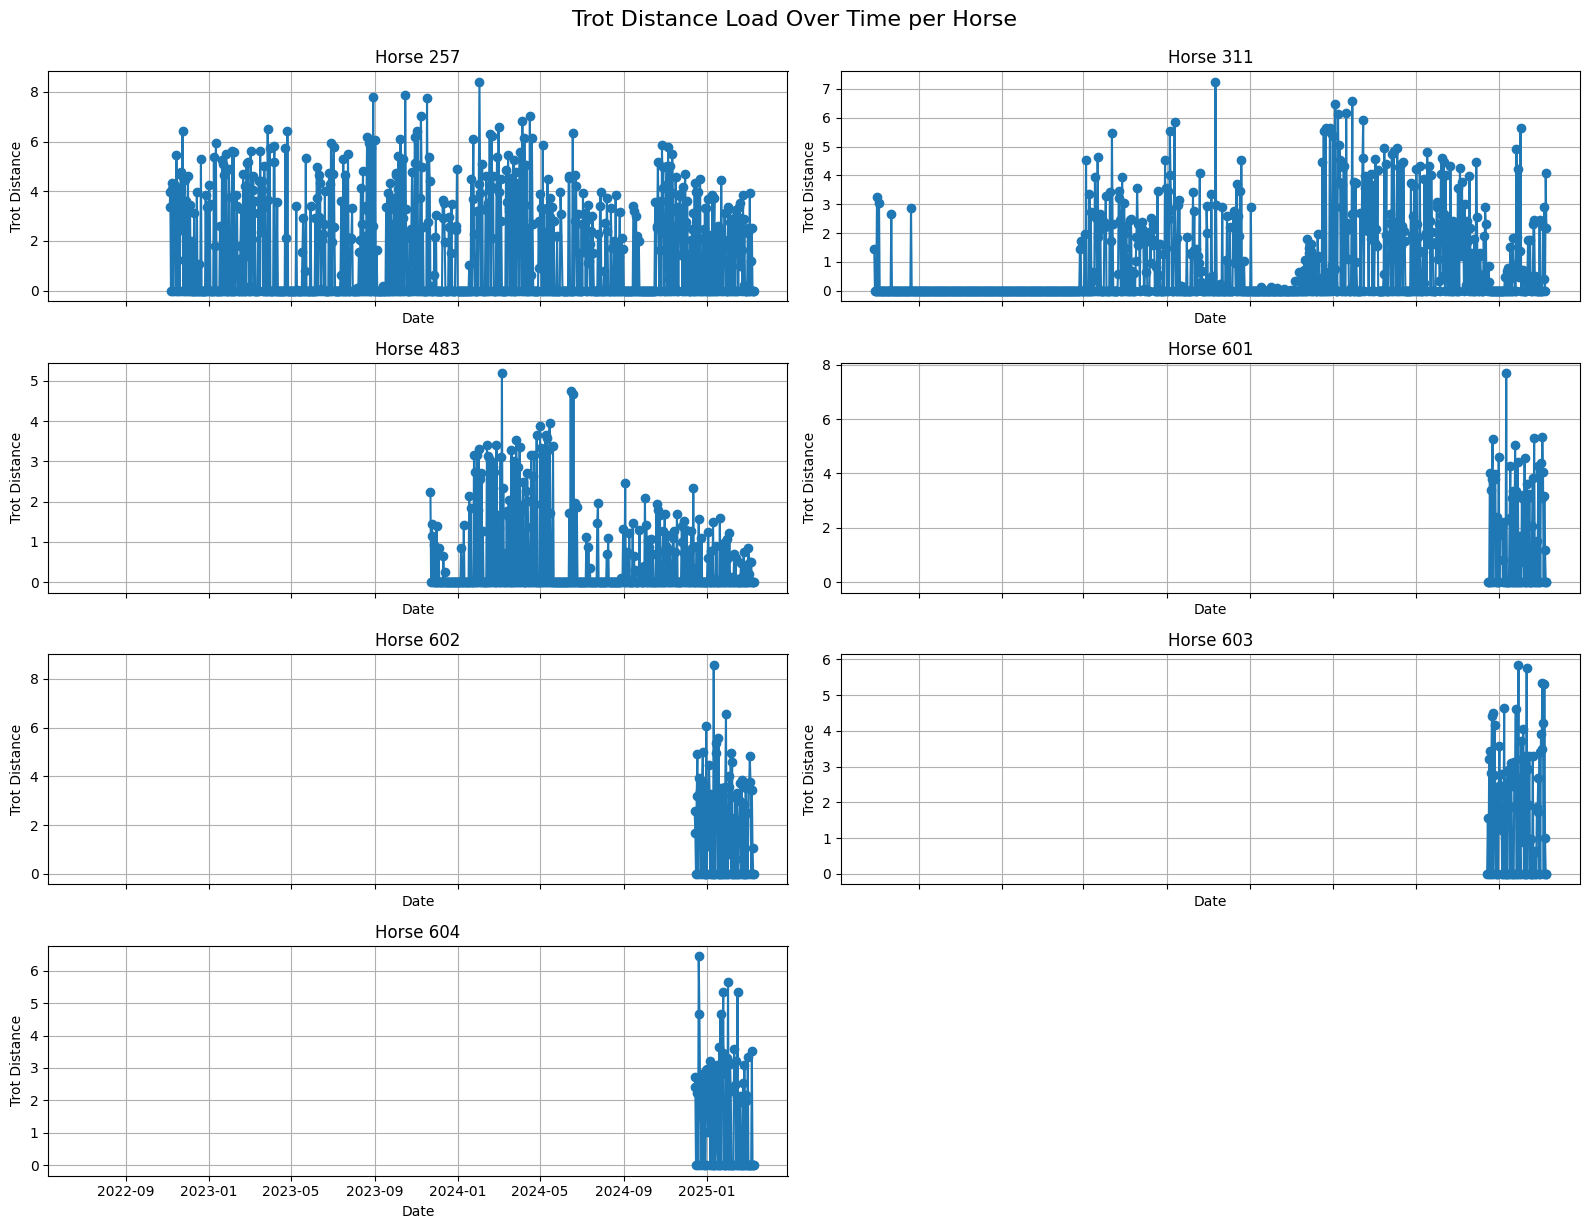

In [6]:
import matplotlib.pyplot as plt

# Filter again to be safe
df_filtered = df[['HorseID', 'Date', metric]].dropna()
df_filtered[metric] = df_filtered[metric].astype(float)

# Get horses and layout
unique_horses = df_filtered['HorseID'].unique()
num_horses = len(unique_horses)
cols = 2  # adjust for layout
rows = (num_horses + 1) // cols

# Create subplots
fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3), sharex=True)
axes = axes.flatten()

for i, horse_id in enumerate(unique_horses):
    horse_df = df_filtered[df_filtered['HorseID'] == horse_id]
    axes[i].plot(horse_df['Date'], horse_df[metric], marker='o', linestyle='-')
    axes[i].set_title(f'Horse {horse_id}')
    axes[i].set_ylabel('Trot Distance')
    axes[i].set_xlabel('Date')
    axes[i].grid(True)

# Hide unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle('Trot Distance Load Over Time per Horse', fontsize=16, y=1.02)
plt.show()


# ACWR Plots

## Plotting ACWR metrics over time
### 1. Distance
What Does externalDistance_Distance_ACWR Represent?

It tells you how much distance a horse covered this week compared to the average it covered over past weeks.

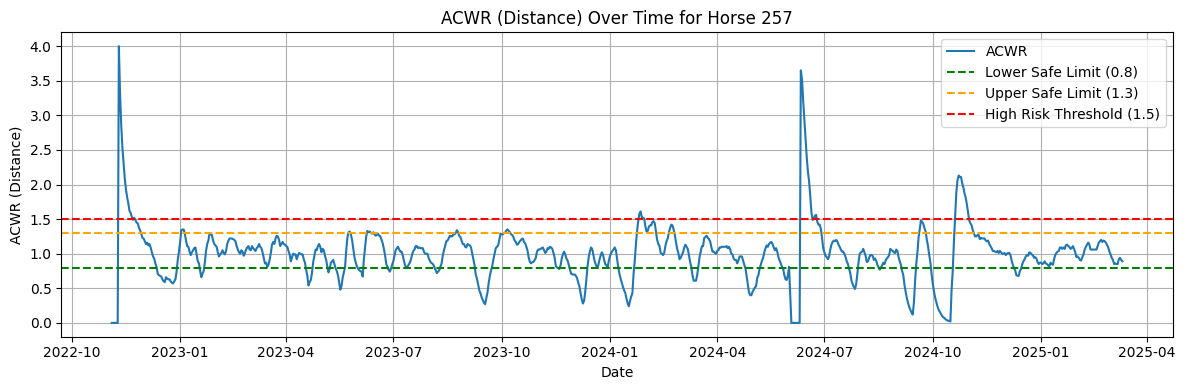

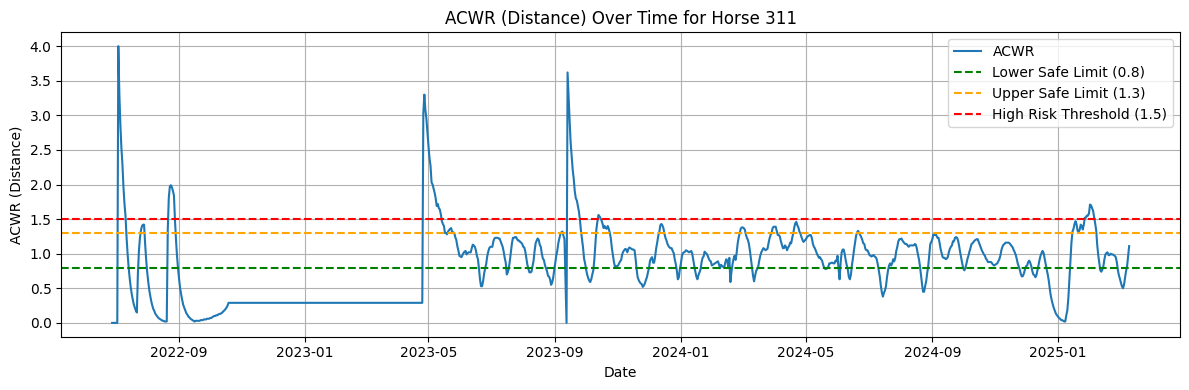

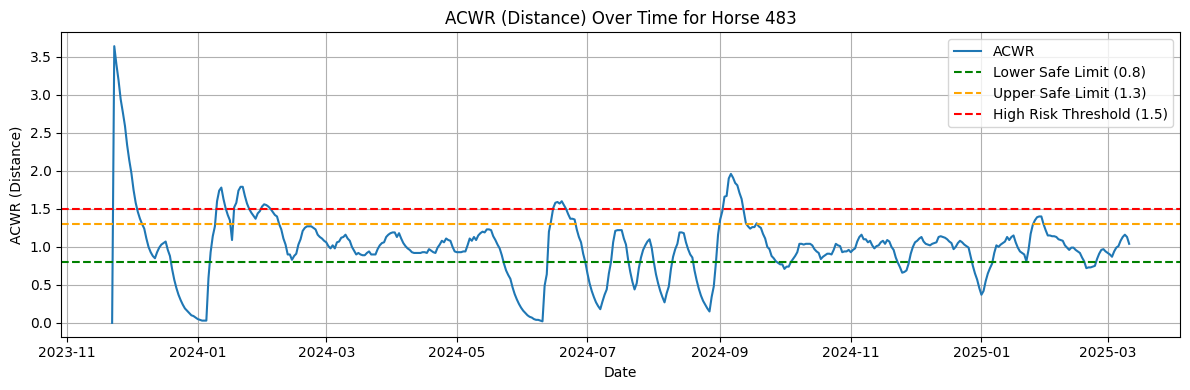

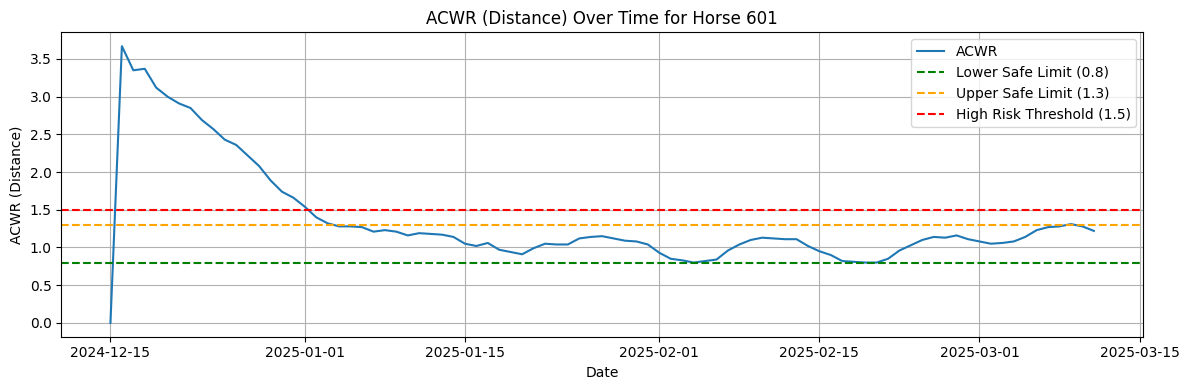

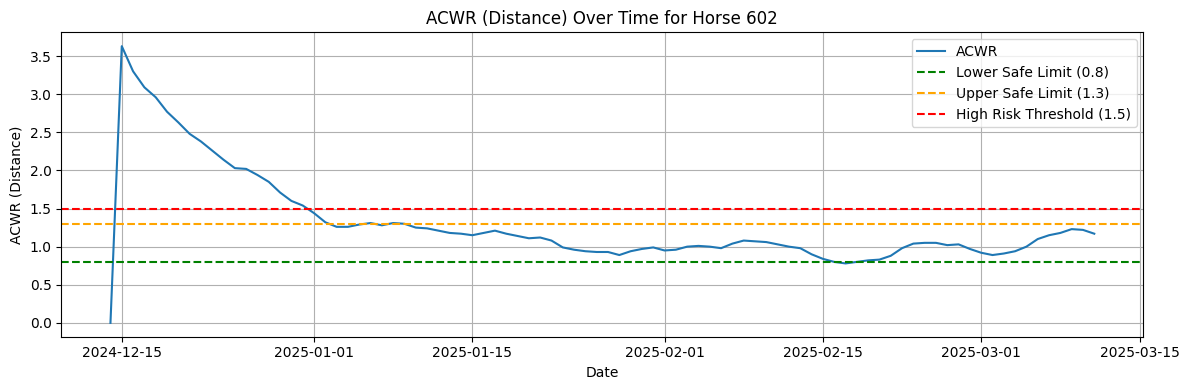

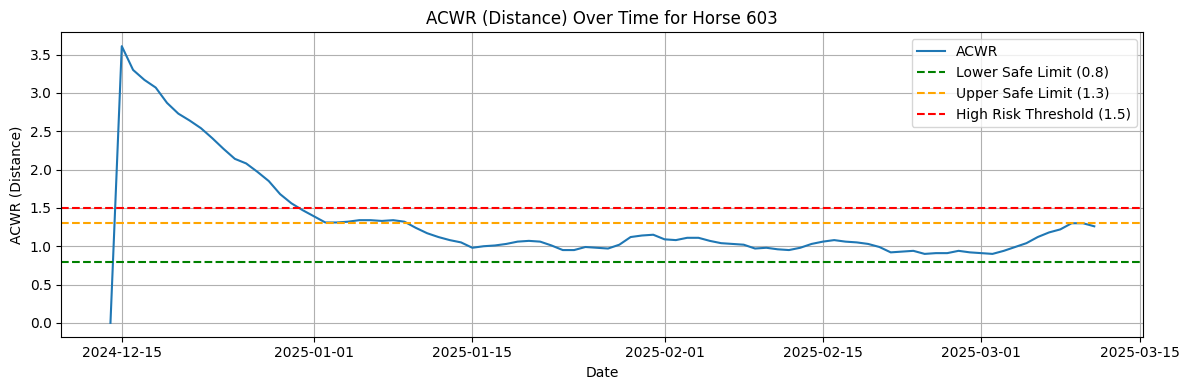

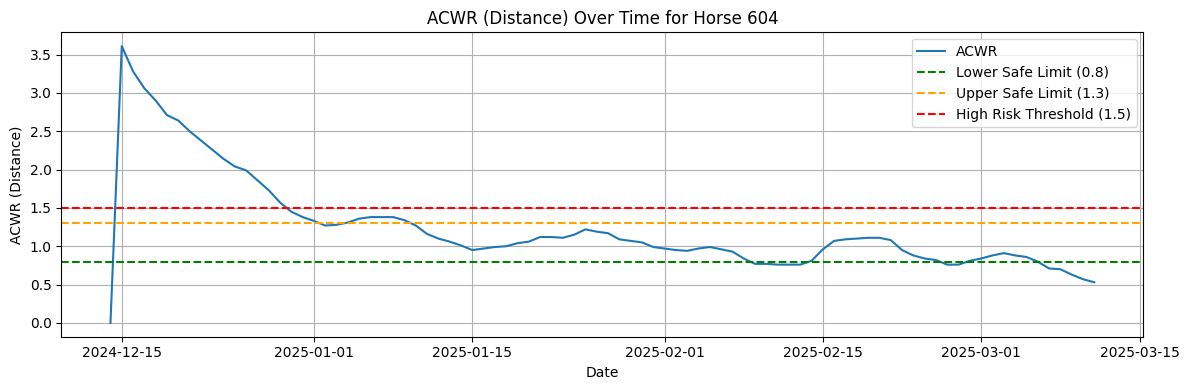

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the ACWR metric column
acwr_col = 'externalDistance_Distance_ACWR'

# Filter and clean data
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: create ACWR risk category
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Get list of horses
horses = df_acwr['HorseID'].unique()

# Plot ACWR over time for each horse
for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # Threshold lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    # Formatting
    plt.title(f'ACWR (Distance) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (Distance)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 2. Duration
What Does externalDuration_Duration_ACWR Represent?

This metric tracks how long a horse trains (in minutes or hours) and compares recent weekly training time to long-term average training time.

ACWR (Duration) = This week's total training time / Average weekly training time over previous weeks

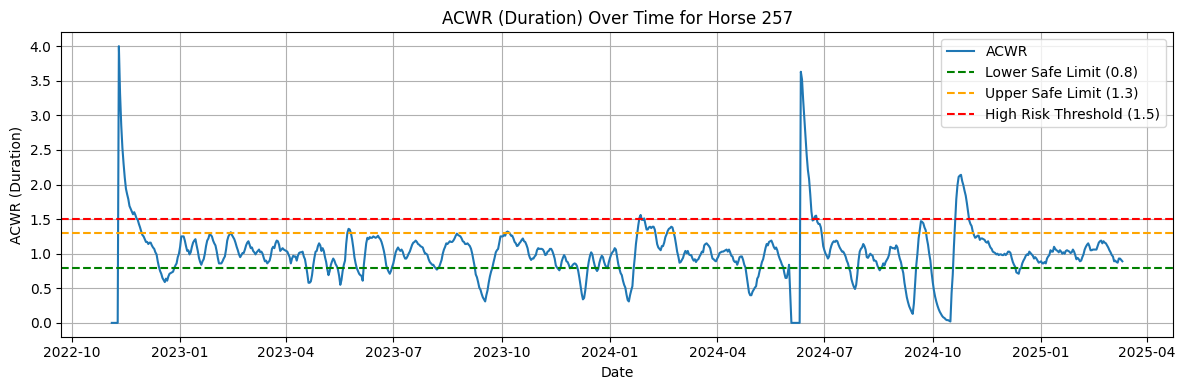

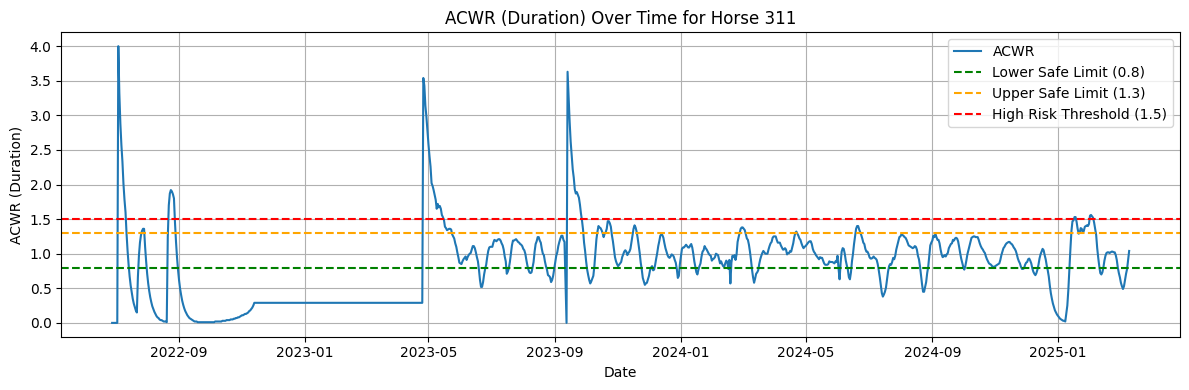

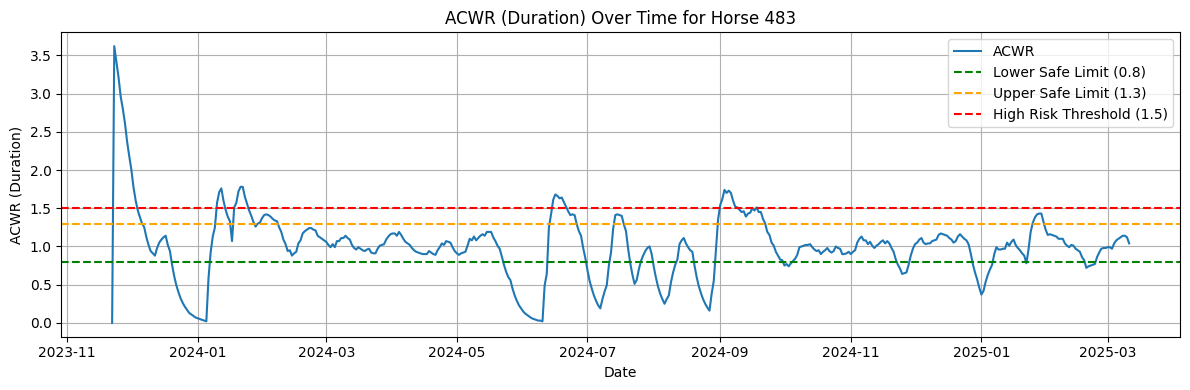

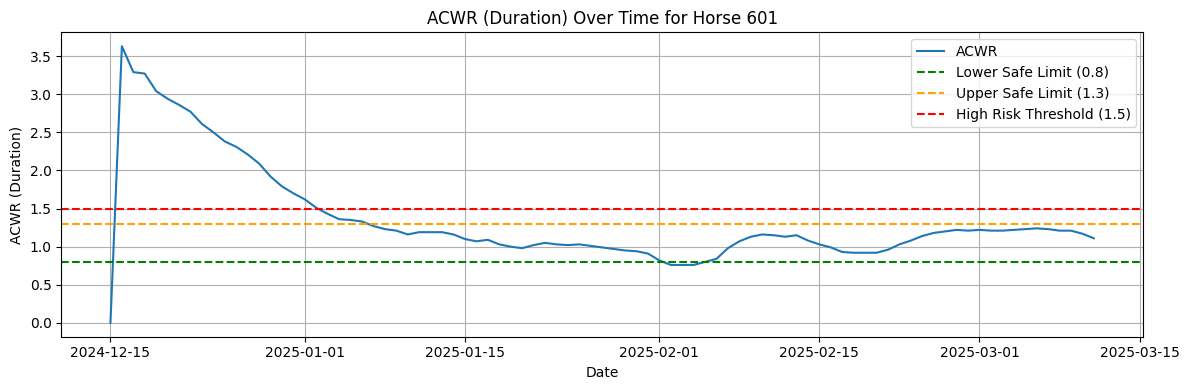

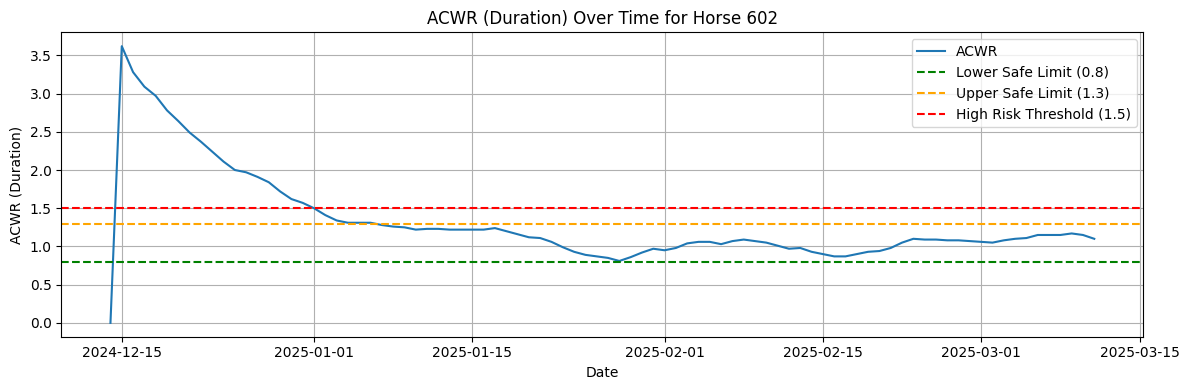

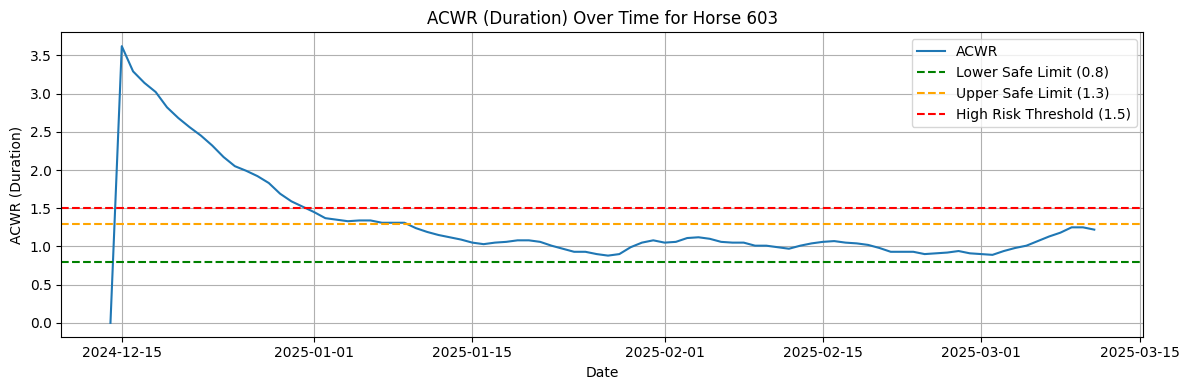

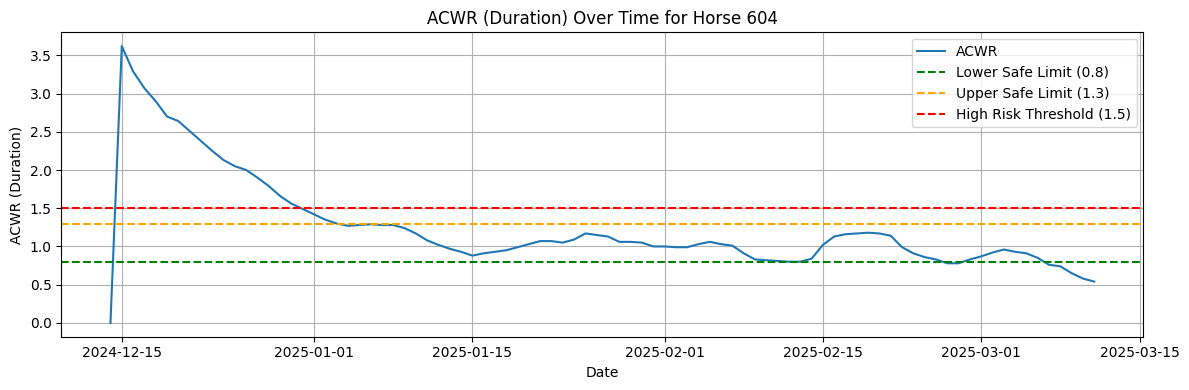

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the ACWR duration metric
acwr_col = 'externalDuration_Duration_ACWR'

# Filter and clean data
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: categorize risk
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # Threshold lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (Duration) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (Duration)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


### 3. iTrimp
What Does eiTrimp_overall_ACWR Represent?

iTRIMP = individualized Training Impulse

iTRIMP ACWR compares the recent week’s internal load to the horse’s chronic internal load average

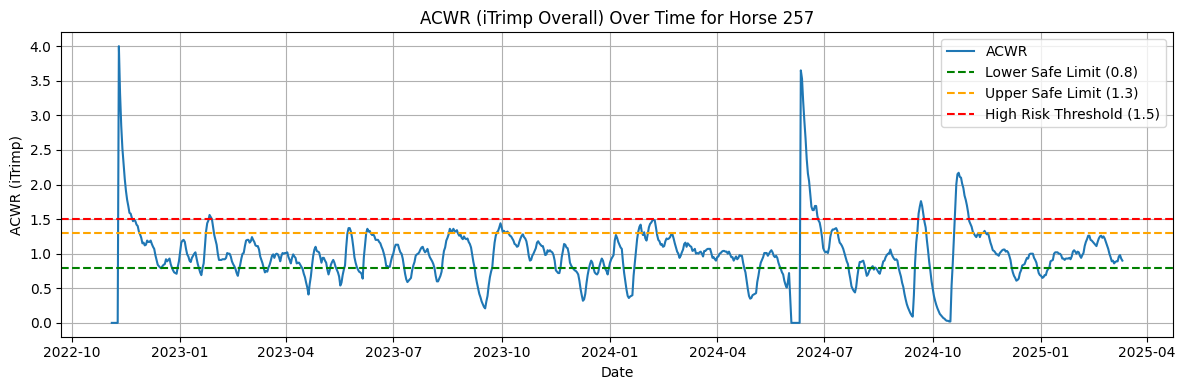

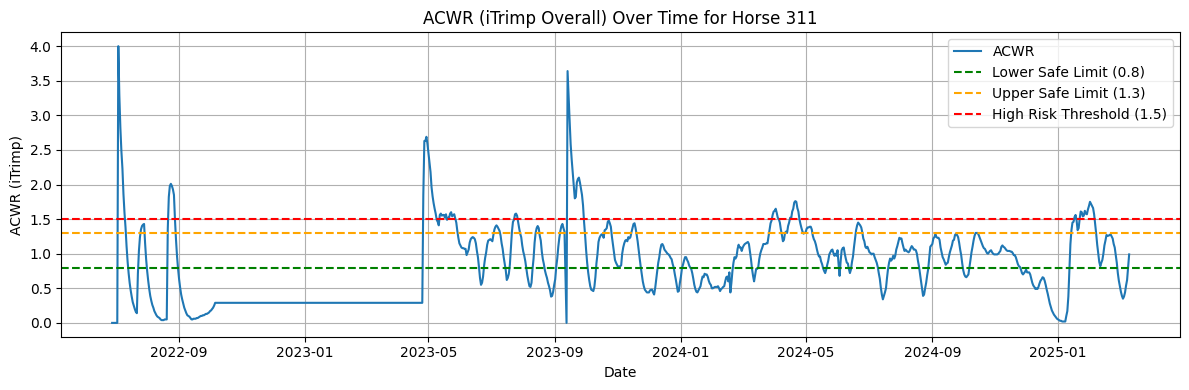

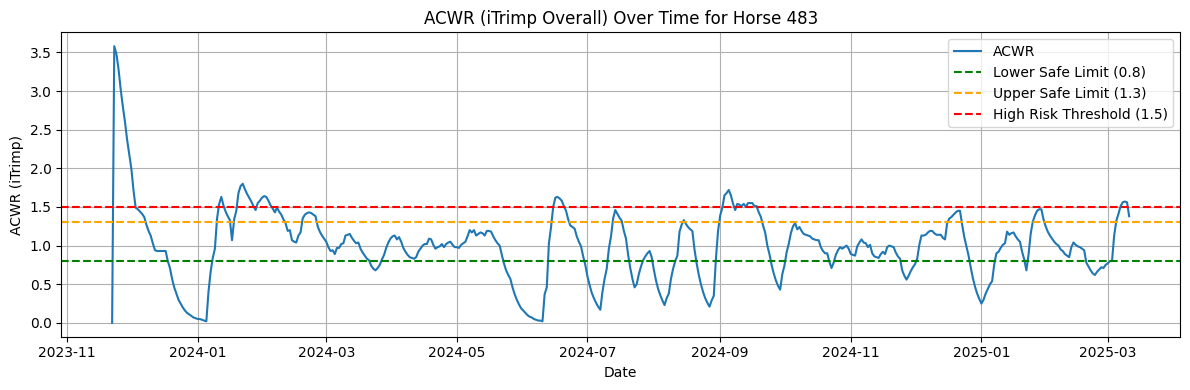

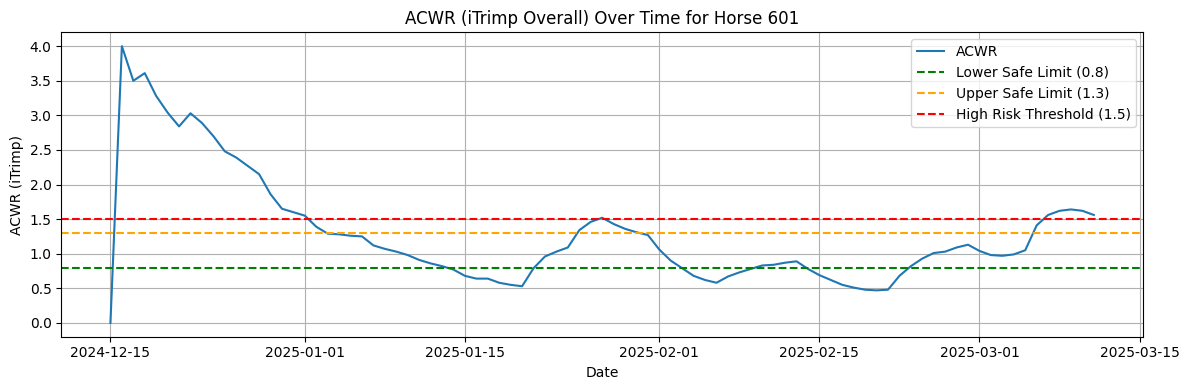

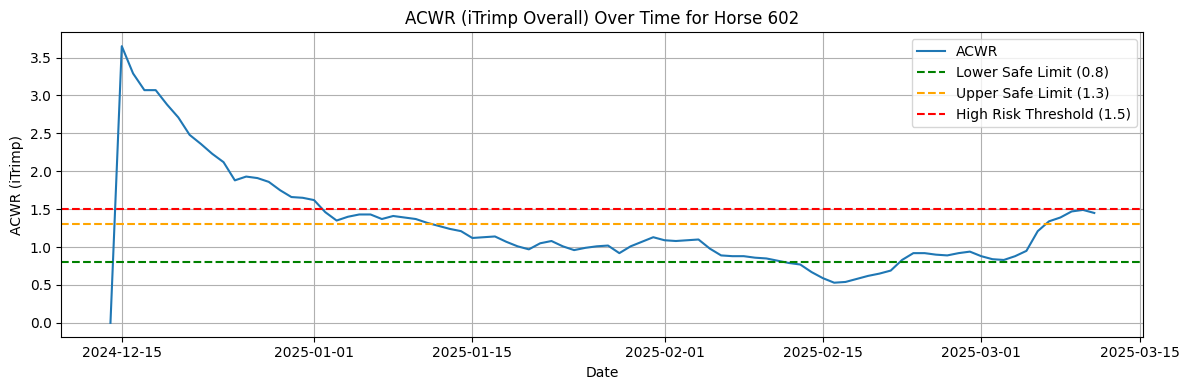

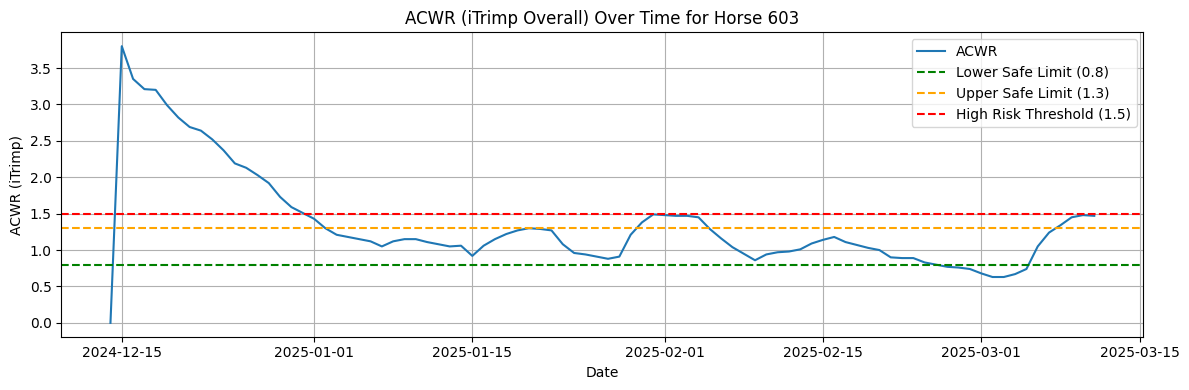

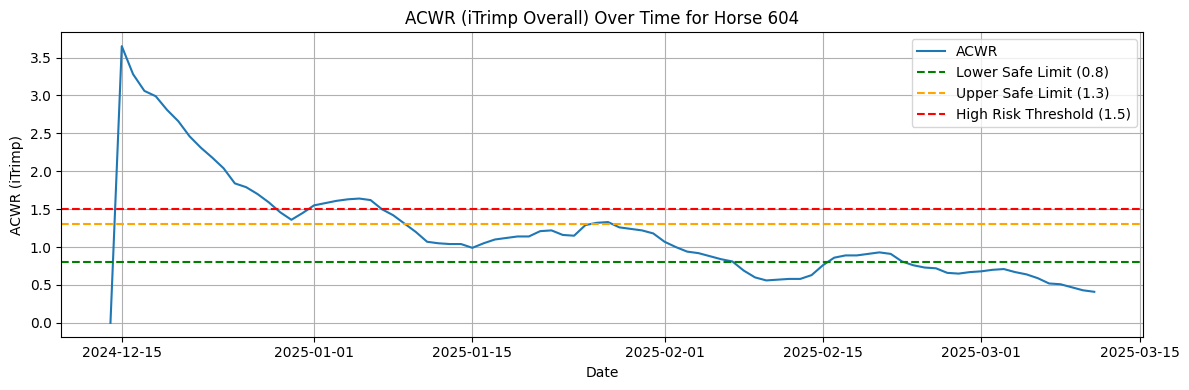

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Combined ACWR Comparison Plot per Horse

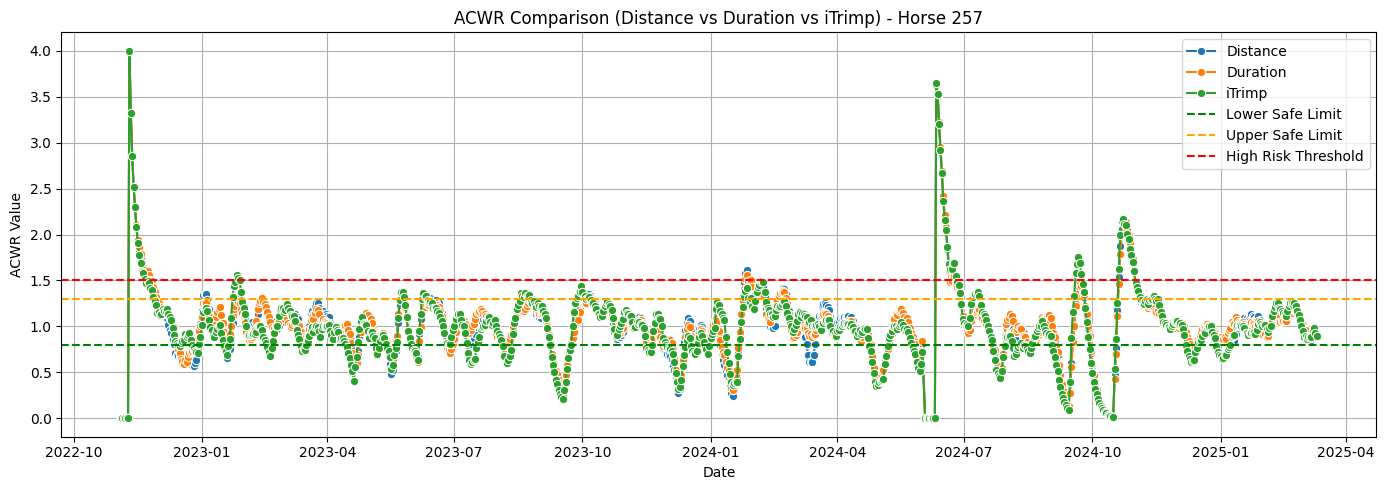

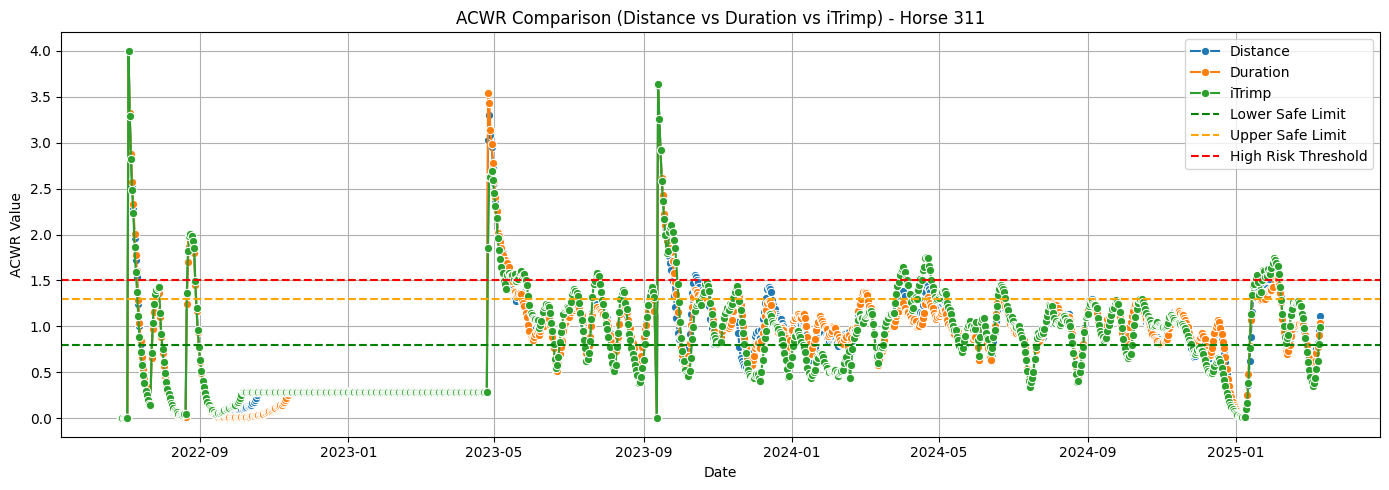

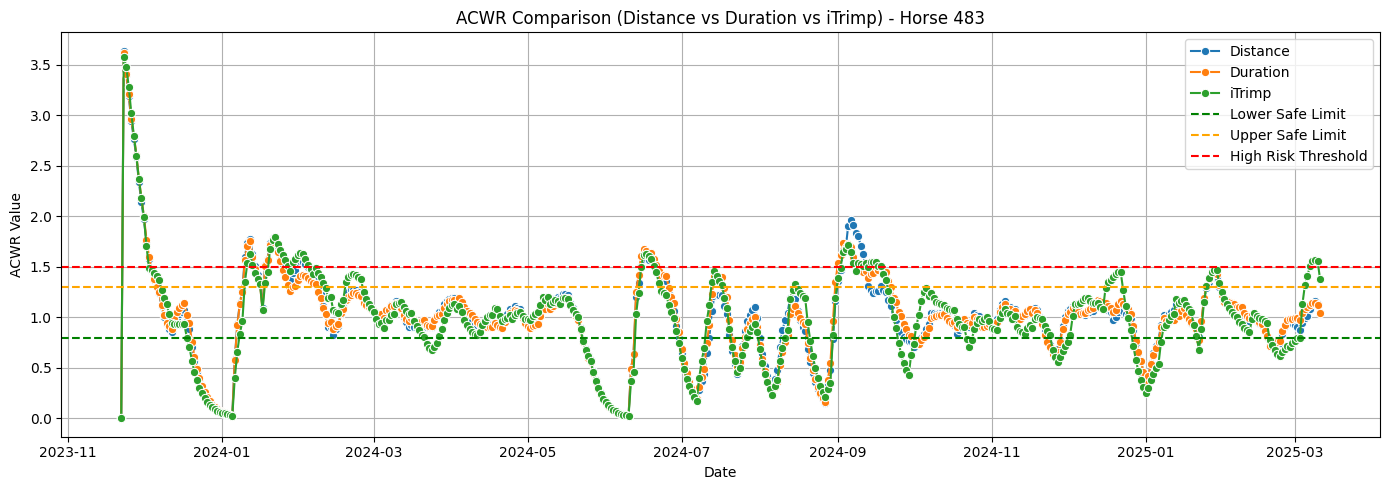

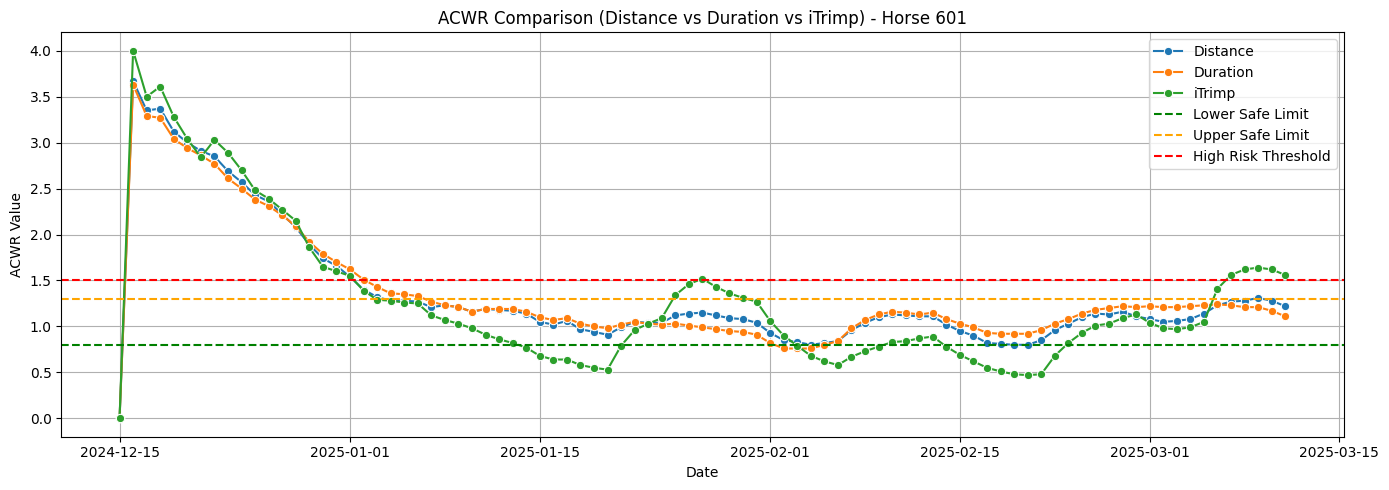

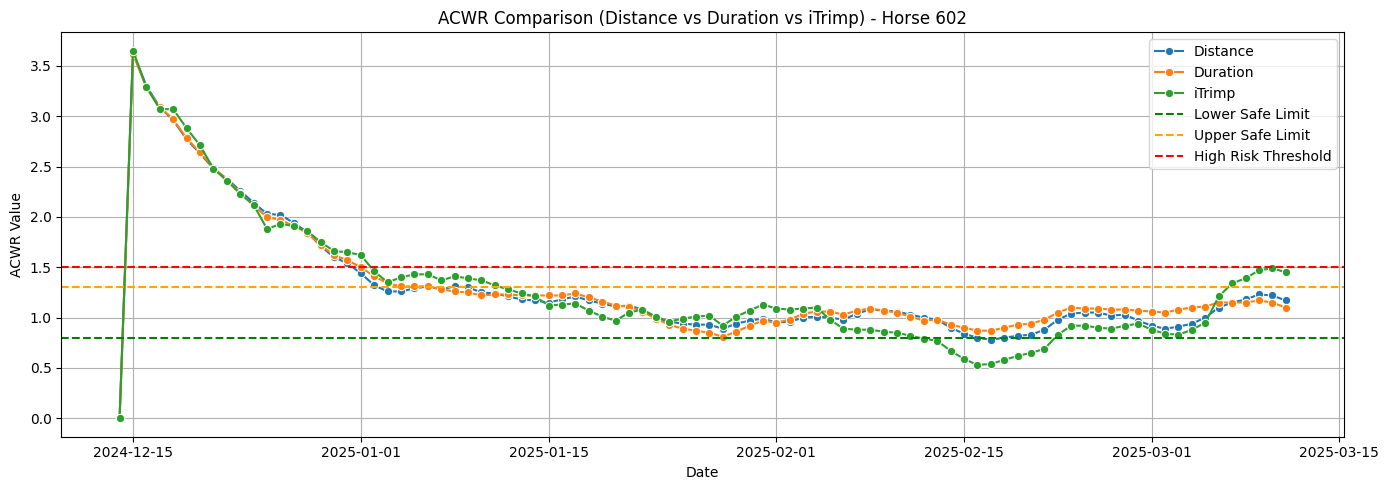

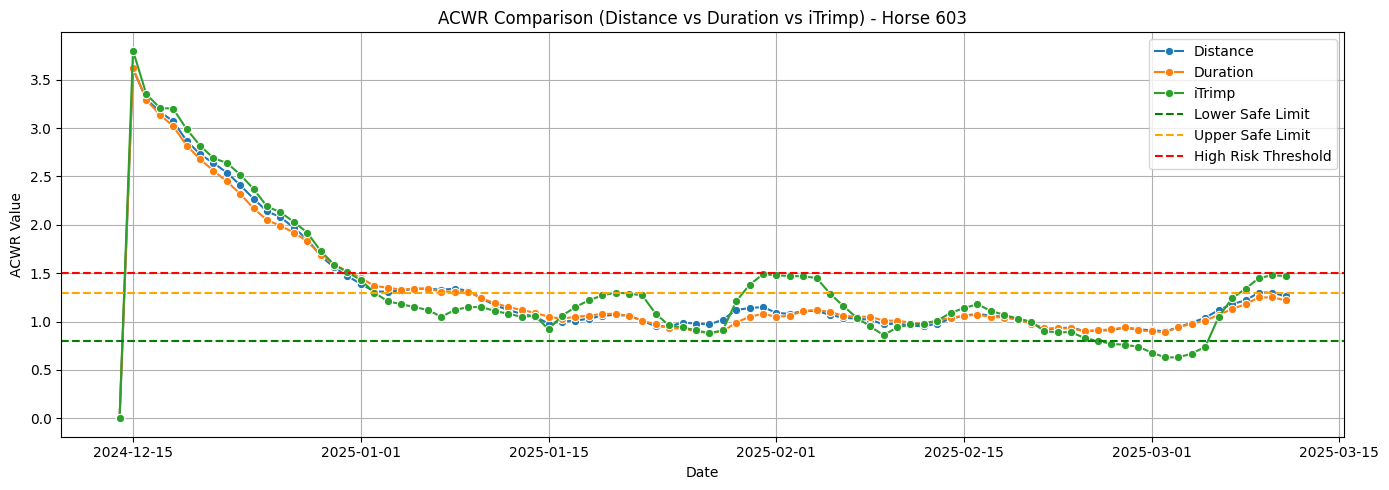

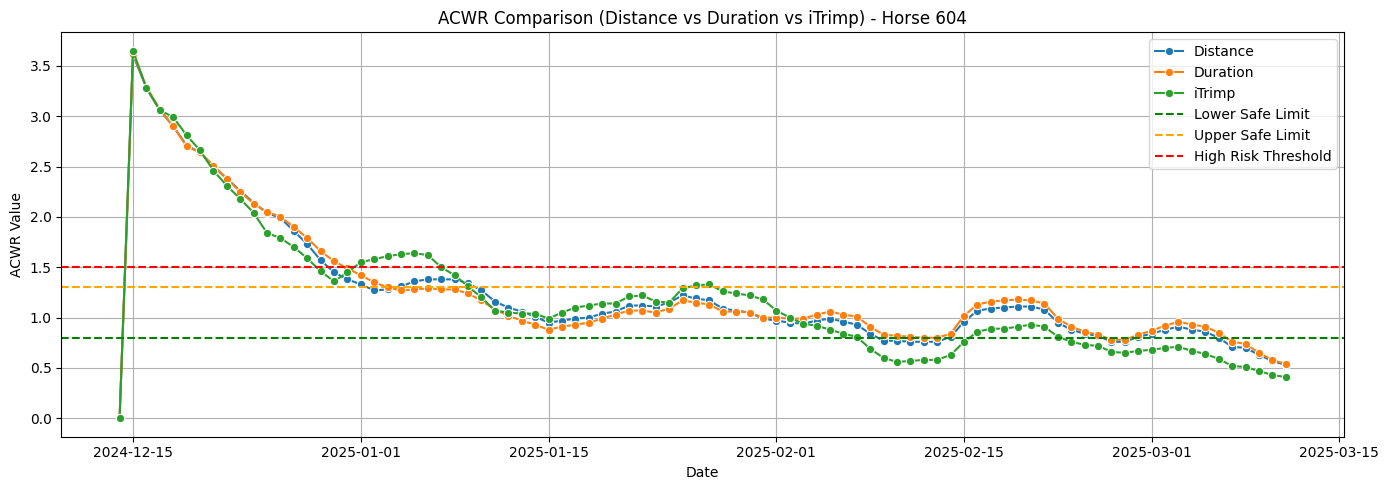

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Distance_ACWR',
    'Duration': 'externalDuration_Duration_ACWR',
    'iTrimp': 'iTrimp_overall_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Distance_ACWR': 'Distance',
    'externalDuration_Duration_ACWR': 'Duration',
    'iTrimp_overall_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
    
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
